# Hyper Instancing Meshes in a BIM Model - 5

In [Hyper Instance-4](hyper-instance-4.ipynb) we attempted to replace all the 90 degree bends in a model with one single piece of geometry that would capture essence of the shape. The work required calculating the scale and pose of a non-symmetric shape and comparing it to a known one. In this notebook, we're moving onto another prevalent shape that tends to overwhelm the memory of our scene- ductwork.

![Ductwork example](../img/ductowrk-example.png)

## Import of modules and packages

In [1]:
import numpy as np
import pygltflib
import pymeshlab
import ifcopenshell
import ifcopenshell.geom
import ifcopenshell.util.shape
import matplotlib.pyplot as plt

In [2]:
model = ifcopenshell.open('data/O-S1-INS-W Installatie.ifc')

## Basic EDA

Here is what our model looks like in Bonsai.

![Overview of HVAC model in Blender Bonsai](../img/ductwork-overview-of-model.png)

Looks similar to our piping model. And majority of the ductwork appears to follow the same cross-sectional shape shown above.

However, there are also instances of perfectly round ducts- as well as perfectly square ducts.

![Ductwork Round and Square Examples](../img/ductwork-round-and-square-examples.png)

Not to mention a myriad of fittings including flattened 90 degree bends. This will be a long and tough one, requiring a consolidation of all our knowledge so far.

![Ductwork Flat 90 Degree Bend](../img/ductwork-flat-90deg-bend.png)

## Plan of Attack

Here is my thinking on how betst to approach this. Given that our input sample has a multitude of different shapes, we will need something like an image classifier ML algorithm to first identify the input shape. This will allow us to then use the same Principal Component Analysis method from earlier to match the pose, scale and position of the input shape to a sample one that is known already. This way, we can boil down our entire model into a series of instanced objects and hopefully retain the same look and feel of it.

Let's first take a sample of objects from the model.

![HVAC Samples from the model](../img/hvac-samples.png)

We have quite a mix of objects in the sample, but ultimately they boil down to 3 cross sectional shapes- the square, the circle, and the round oval. We can create simple unit objects for our test case as well. Here, we import them as standalone meshes.

In [16]:
# Reintroduce the plotting function here
def plot_vertices(vertices, cmap='grey'):
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')
    
    ax.scatter(vertices[:,0], vertices[:,1], vertices[:,2], c=vertices[:,1], cmap=cmap)

    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')

    return ax

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

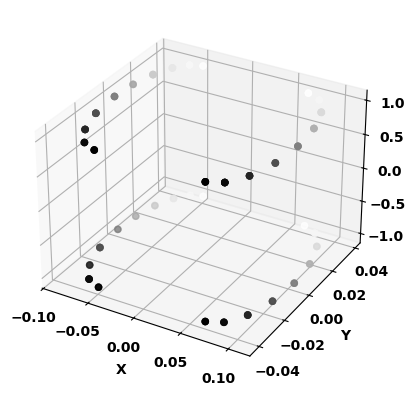

In [8]:
ms = pymeshlab.MeshSet()

ms.load_new_mesh('data/oval-duct-test.obj')
m_1 = ms.current_mesh()

v_matrix_oval = m_1.vertex_matrix()
plot_vertices(v_matrix_oval)

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

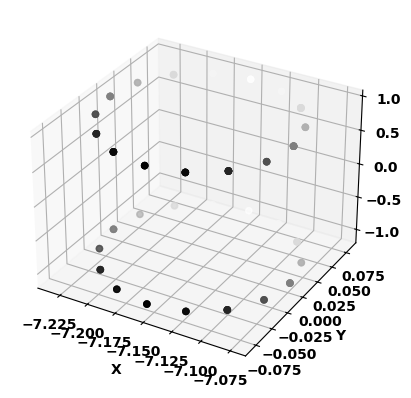

In [9]:
ms.load_new_mesh('data/circular-duct-test.obj')
m_2 = ms.current_mesh()

v_matrix_circle = m_2.vertex_matrix()
plot_vertices(v_matrix_circle)

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

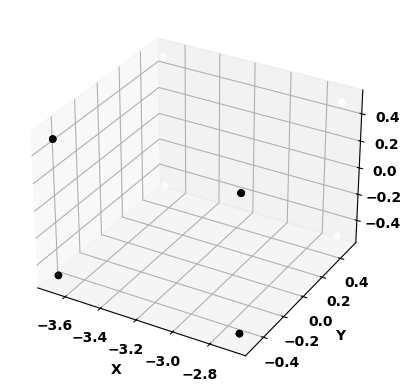

In [11]:
ms.load_new_mesh('data/sqaure-duct-test.obj')
m_3 = ms.current_mesh()

v_matrix_square = m_3.vertex_matrix()
plot_vertices(v_matrix_square)

Here, our sqaure duct is actually just a simple cube. We will revisit this primitive if we start running into issues.

Since we have already addressed the circular cross section before, we shall devote our efforts into working with the oval duct. If we remove the depth shading from our `plot_vertices` function, we should get the entire shape of the object.

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

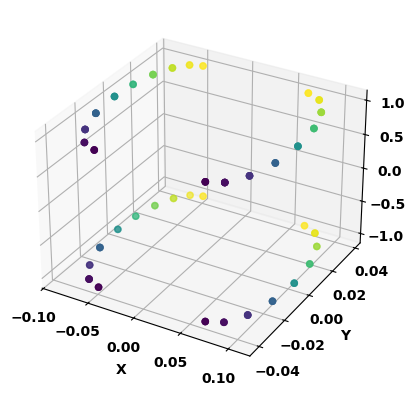

In [20]:
plot_vertices(v_matrix_oval, cmap=None)